# 02 · Qualidade dos dados e transformação → camada silver

**MVP — Onde subsidiar o frete no e-commerce brasileiro: pipeline de dados em nuvem (Databricks)**

Universidade de Brasília (UnB) · Departamento de Engenharia de Produção · Sistemas de Suporte à Decisão
Prof. André Luiz Marques Serrano · **Aluna: Brunna Gavião Moraes — 231025341**


A análise de qualidade vem **antes** da transformação, porque é ela que define as regras de tratamento:

1. perfil de **todos os atributos** dos 10 arquivos da bronze;
2. **33 verificações** em sete dimensões (completude, unicidade, conformidade, consistência, acurácia, integridade e
   atualidade), cada uma ligada ao tratamento adotado;
3. regras **R01–R13**, que geram as tabelas da camada silver (Delta) e registram a linhagem.

In [0]:
%pip install -q kagglehub statsmodels

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# Configuração comum: localiza o repositório, importa o módulo de apoio e detecta a plataforma.
# No Databricks a variável `spark` já existe; fora dele o mesmo código roda localmente (Parquet + DuckDB).
import os, sys, importlib
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import mvp_frete as mvp
importlib.reload(mvp)

import pandas as pd
pd.set_option("display.max_columns", 50, "display.width", 200)

plat = mvp.Plataforma(spark if "spark" in globals() else None)
print("Ambiente :", plat.preparar())
print("Bronze   :", plat.dir_bronze)
print("Evidências:", plat.dir_evidencias)

Ambiente : Databricks — catálogo workspace, schemas frete_bronze, frete_silver, frete_gold
Bronze   : /Volumes/workspace/frete_bronze/arquivos
Evidências: /Workspace/Users/brunnagmoraes17@gmail.com/MVP3-SSD-Frete-Olist/evidencias


## 1. Leitura da bronze e conferência dos hashes

In [0]:
import json
dir_coleta = sorted(p for p in plat.dir_bronze.iterdir() if p.name.startswith("coleta="))[-1]
meta = json.loads((dir_coleta / "_metadados_coleta.json").read_text(encoding="utf-8"))
conf = pd.DataFrame([{"arquivo": m["arquivo"], "hash_confere": mvp.sha256(dir_coleta / m["arquivo"]) == m["sha256"]}
                     for m in meta["arquivos"]])
assert conf.hash_confere.all(), "Arquivo da bronze alterado depois da coleta!"
print("Coleta usada:", dir_coleta.name, "· hashes conferidos:", conf.hash_confere.sum(), "de", len(conf))

b = mvp.ler_bronze(dir_coleta)   # tudo lido como texto: nenhuma conversão silenciosa
display(pd.DataFrame({t: [len(df), df.shape[1]] for t, df in b.items()}, index=["linhas", "colunas"]).T)

Coleta usada: coleta=2026-11-09 · hashes conferidos: 10 de 10


linhas,colunas
99441,8
112650,7
99441,5
3095,4
32951,9
99224,7
103886,5
1000163,5
71,2
27,4


## 2. Perfil de todos os atributos

Para cada atributo: tipo esperado, nulos, valores distintos, % de valores conformes ao tipo, mínimo, máximo e valores
mais frequentes.

In [0]:
perfil = mvp.perfil_atributos(b)
mvp.salvar_tabela_evidencia(perfil, plat, "q1_perfil_por_atributo")
print(len(perfil), "atributos perfilados ·", (perfil.nulos > 0).sum(), "com nulos ·",
      (perfil.pct_conformidade_tipo < 100).sum(), "com valores fora do tipo")
display(perfil)

56 atributos perfilados · 13 com nulos · 0 com valores fora do tipo


tabela,atributo,tipo_esperado,linhas,nulos,pct_nulos,distintos,pct_conformidade_tipo,minimo,maximo,mais_frequentes
orders,order_id,hash,99441,0,0.0,99441,100.0,null,null,null
orders,customer_id,hash,99441,0,0.0,99441,100.0,null,null,null
orders,order_status,texto,99441,0,0.0,8,100.0,approved,unavailable,delivered (96478); shipped (1107); canceled (625)
orders,order_purchase_timestamp,data,99441,0,0.0,98875,100.0,2016-09-04 21:15:19,2018-10-17 17:30:18,2018-04-11 10:48:14 (3); 2018-07-28 13:11:22 (3); 2017-11-20 10:59:08 (3)
orders,order_approved_at,data,99441,160,0.16,90733,100.0,2016-09-15 12:16:38,2018-09-03 17:40:06,2018-02-27 04:31:10 (9); 2017-11-07 07:30:38 (7); 2018-02-27 04:31:01 (7)
orders,order_delivered_carrier_date,data,99441,1783,1.79,81018,100.0,2016-10-08 10:34:01,2018-09-11 19:48:28,2018-05-09 15:48:00 (47); 2018-05-10 18:29:00 (32); 2018-05-07 12:31:00 (21)
orders,order_delivered_customer_date,data,99441,2965,2.98,95664,100.0,2016-10-11 13:46:32,2018-10-17 13:22:46,2018-05-08 23:38:46 (3); 2016-10-27 17:32:07 (3); 2018-02-14 21:09:19 (3)
orders,order_estimated_delivery_date,data,99441,0,0.0,459,100.0,2016-09-30 00:00:00,2018-11-12 00:00:00,2017-12-20 00:00:00 (522); 2018-03-12 00:00:00 (516); 2018-05-29 00:00:00 (513)
order_items,order_id,hash,112650,0,0.0,98666,100.0,null,null,null
order_items,order_item_id,inteiro,112650,0,0.0,21,100.0,1,21,1 (98666); 2 (9803); 3 (2287)


## 3. Verificações por dimensão de qualidade

In [0]:
verif = mvp.verificacoes_qualidade(b)
mvp.salvar_tabela_evidencia(verif, plat, "q2_verificacoes_por_dimensao")
display(verif.groupby("dimensao", sort=False).agg(verificacoes=("verificacao", "size"),
                                                  com_ocorrencia=("ocorrencias", lambda x: (x > 0).sum())))
display(verif)

verificacoes,com_ocorrencia
6,5
6,2
7,1
3,2
4,3
6,2
1,1


dimensao,tabela,verificacao,ocorrencias,total,pct,tratamento
Completude,products,produto sem categoria,610,32951,1.851,R05: categoria 'sem_categoria'
Completude,products,produto sem peso ou sem alguma dimensão,2,32951,0.006,R06: medidas nulas + flag; peso taxado usa o que existir
Completude,orders,pedido sem data de aprovação,160,99441,0.161,Sem impacto: a análise usa a data da compra
Completude,orders,pedido sem nenhum item,775,99441,0.779,R08: fora do escopo (sem frete a analisar)
Completude,order_items,item sem preço ou sem frete,0,112650,0.0,Nenhum caso
Completude,order_reviews,pedido sem avaliação,768,99441,0.772,nota nula na fato (atributo opcional)
Unicidade,orders,order_id duplicado,0,99441,0.0,Nenhum caso
Unicidade,order_items,"par (order_id, order_item_id) duplicado",0,112650,0.0,Nenhum caso
Unicidade,products,product_id duplicado,0,32951,0.0,Nenhum caso
Unicidade,sellers,seller_id duplicado,0,3095,0.0,Nenhum caso


## 4. Atualidade: volume mensal e janela de análise

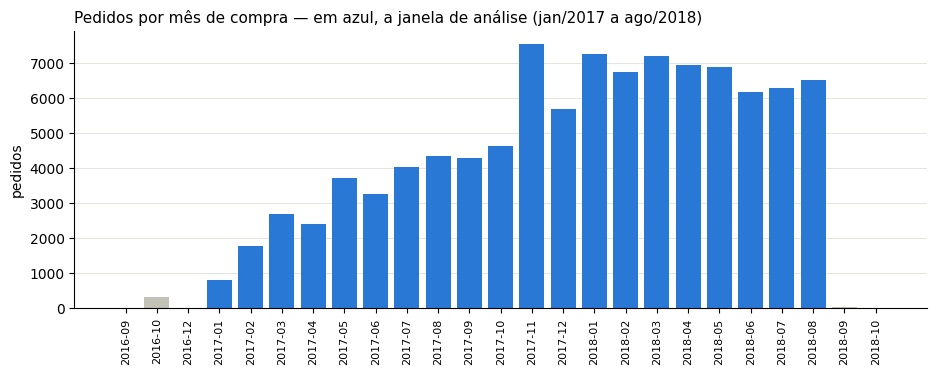

In [0]:
import matplotlib.pyplot as plt
vol = mvp.volume_mensal(b)
mvp.salvar_tabela_evidencia(vol, plat, "q3_volume_mensal")

fig, ax = plt.subplots(figsize=(11, 3.6))
cores = ["#2a78d6" if j else "#c3c2b7" for j in vol.na_janela]
ax.bar(vol.ano_mes, vol.pedidos, color=cores, width=0.8)
ax.set_title("Pedidos por mês de compra — em azul, a janela de análise (jan/2017 a ago/2018)", loc="left", fontsize=11)
ax.set_ylabel("pedidos")
ax.tick_params(axis="x", rotation=90, labelsize=8)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="y", color="#e1e0d9", linewidth=0.6); ax.set_axisbelow(True)
mvp.salvar_figura(fig, plat, "q3_volume_mensal"); plt.show()

### Leitura da qualidade

* **A base é íntegra nas chaves:** nenhum pedido, item, produto ou vendedor duplicado, e nenhuma chave estrangeira órfã
  entre itens, produtos, vendedores e clientes.
* **Os problemas que afetam o frete são poucos e têm tratamento explícito:**
  * produtos sem categoria (R05);
  * 4 produtos com peso zero, tratados como ausentes, e 2 sem medidas (R06);
  * coordenadas fora do Brasil, descartadas antes do centroide (R04);
  * CEPs sem geolocalização, que deixam a distância nula, sem excluir o item (R10).
* **Valores extremos que são o próprio fenômeno estudado foram mantidos e sinalizados:**
  * frete maior que o preço do item;
  * frete zero (frete grátis).
* **Atualidade:** 2016 tem volume irrisório e set–out/2018 está truncado. A janela vai de **jan/2017 a ago/2018**
  (R08), com 20 meses completos.

## 5. Transformação bronze → silver (R01–R13)

In [0]:
log = mvp.LogLinhagem()
S = mvp.transformar_silver(b, log)
comentarios = {
    "pedidos": "Pedidos no escopo (jan/2017–ago/2018, exceto cancelados/indisponíveis) — R01, R08",
    "itens": "Itens dos pedidos no escopo, com preço e frete em R$ — R01, R08",
    "clientes": "Clientes: CEP (5 dígitos), cidade e UF; sem identificador único (LGPD) — R02, R03, R13",
    "vendedores": "Vendedores: CEP (5 dígitos), cidade e UF — R02, R03",
    "produtos": "Produtos com categoria, medidas, peso cubado e peso taxado — R05, R06",
    "avaliacoes": "Uma avaliação por pedido, sem texto livre — R07, R13",
    "geo_cep": "Centroide (mediana) de latitude e longitude por prefixo de CEP — R04",
    "ibge_uf": "População estimada 2018 por UF (IBGE), chaveada pela sigla — R12",
}
linhas_silver = []
for tabela, df in S.items():
    n = plat.gravar(df, "silver", tabela, comentarios[tabela])
    linhas_silver.append({"tabela": plat.nome_tabela("silver", tabela), "linhas": n, "colunas": df.shape[1]})
display(pd.DataFrame(linhas_silver))

tabela,linhas,colunas
workspace.frete_silver.geo_cep,19010,5
workspace.frete_silver.produtos,32951,11
workspace.frete_silver.avaliacoes,98673,3
workspace.frete_silver.pedidos,97905,6
workspace.frete_silver.itens,111752,7
workspace.frete_silver.clientes,99441,4
workspace.frete_silver.vendedores,3095,4
workspace.frete_silver.ibge_uf,27,6


In [0]:
log_df = log.df()
plat.gravar(log_df, "silver", "meta_log_transformacoes", "Log de linhagem das regras aplicadas na silver")
display(log_df)

regra,camada_destino,tabela,descricao,linhas_afetadas,linhas_resultantes,executado_em
R01,silver,pedidos/itens,"Tipagem: datas como timestamp, preço e frete como decimal (R$), sequência do item como inteiro",212091,212091,2026-11-09T15:00:15
R02,silver,clientes/vendedores,Prefixo de CEP padronizado com 5 dígitos (zeros à esquerda),0,102536,2026-11-09T15:00:15
R03,silver,clientes/vendedores,UF em maiúsculas e validada nas 27 UFs; cidade em minúsculas sem acento,0,102536,2026-11-09T15:00:15
R04,silver,geo_cep,Descarta coordenadas fora do território brasileiro e resume a geolocalização em um centroide (mediana) por prefixo de CEP,981153,19010,2026-11-09T15:00:17
R05,silver,produtos,Categoria ausente recebe 'sem_categoria' (mantém o item na análise),610,32951,2026-11-09T15:00:17
R06,silver,produtos,Converte g→kg; peso cubado = C×A×L (cm³) ÷ 6000; peso taxado = maior entre peso real e cubado; medidas nulas ou zero viram nulo + flag,6,32951,2026-11-09T15:00:17
R07,silver,avaliacoes,Uma avaliação por pedido: mantém a respondida por último; texto livre descartado (ver R13),551,98673,2026-11-09T15:00:17
R08,silver,pedidos,"Escopo: compras de jan/2017 a ago/2018, exceto pedidos cancelados ou indisponíveis (não geraram envio) e pedidos sem itens",1536,97905,2026-11-09T15:00:17
R13,silver,clientes/avaliacoes,"Minimização (LGPD): customer_unique_id, título e texto das avaliações não seguem para silver e gold",198665,198114,2026-11-09T15:00:17
R12,silver,ibge_uf,Conciliação Olist × IBGE: código IBGE da UF convertido em sigla (chave comum às duas bases); região atribuída pela sigla,0,27,2026-11-09T15:00:17


> **Evidência a capturar:** *Catalog Explorer → workspace → frete_silver* com as tabelas criadas
> (`evidencias/02_silver_tabelas.png`).